# DEL 1 :Grundläggande analys och statistik

### 1.1. Import och datainläsning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats



### 1.2. Datainläsning

In [2]:
df = pd.read_csv("../data/health_study_dataset (1).csv")

### 1.3. Basvärde

In [3]:
bp_values = df["systolic_bp"].dropna()
bp_count = len(bp_values)
bp_mean = bp_values.mean()
bp_std = bp_values.std(ddof=1)
bp_se = bp_std / np.sqrt(bp_count)


### 1.4. Konstanter

In [4]:
RANDOM_SEED = 42
ALPHA = 0.05
BP_COLUMN = "systolic_bp"
SEX_COLUMN = ["F", "M"]
SMOKER_COLUMN = ["No", "Yes"]
SIM_GROUP_SIZE = 1000
N_BOOTSTRAP = 50000
BOOTSTRAP_START = 500
BOOTSTRAP_STEP = 1000
N_POWER_SIM = 10000
POWER_SAMPLE_SIZE = [100, 300, 700, 1500, 2500]

### 1.5. Färgpalett och figurstil för visualisering

In [5]:
COLORS = {
    "blood_pressure": "#1ADF8D",
    "blood_pressure_light": "#3B8055",
    "non_smoker": "#8A8029",
    "smoker": "#05565F",
    "female": "#805392",
    "male": "#478D47",
    "reference": "#AA0673",
    "ink": "#070A00",
    "muted": "#423F40",
}

SMOKING_COLORS = {"No": COLORS["non_smoker"], "Yes": COLORS["smoker"]}
SEX_colors = {"F": COLORS["female"], "M": COLORS["male"]}

### 1.6. Graf - visualisering

In [6]:
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor":  "#FFFFFF",
    "savefig.dpi": 150,

    "font.family":  "DejaVu Sans",
    "font.size": 10,
    "text.color": COLORS["ink"],
   
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.facecolor": "#FFFFFF",
    "axes.labelsize": 10,
    "axes.labelcolor": COLORS["ink"],
    "axes.edgecolor": "#9C9494",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,

    "xtick.color": COLORS["muted"],
    "ytick.color": COLORS["muted"],

    "grid.color": "#A79A9A",

    "legend.frameon": False,
})

def style_axis(axis, grid_axis="y"):
    axis.grid(axis=grid_axis, linewidth=0.8)
    axis.spines["left"].set_alpha(0.7)
    axis.spines["bottom"].set_alpha(0.7)

## 2. Översikt över datasetet

### 2.1. Datasetets struktur och datatyper

In [7]:
display(df.head(3))
display(df.tail(3))

print(f"\nDatasetet  --  -  Antal rader: {df.shape[0]}  --  Antal kolumner: {df.shape[1]}")

print(f"\n{"Kolumnamn": <20} Datatype:")
for column in df.columns:
    print(f" - {column: <15} : {df[column].dtype}")

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
797,798,60,F,175.0,49.7,146.5,5.57,No,0
798,799,50,F,172.6,55.3,155.0,3.58,No,0
799,800,50,M,189.2,79.4,139.7,5.62,No,0



Datasetet  --  -  Antal rader: 800  --  Antal kolumner: 9

Kolumnamn            Datatype:
 - id              : int64
 - age             : int64
 - sex             : str
 - height          : float64
 - weight          : float64
 - systolic_bp     : float64
 - cholesterol     : float64
 - smoker          : str
 - disease         : int64


### 2.2. Datavalidering och datarensning

In [8]:
expected_values = ({df.columns[0]: df["id"].is_unique,
                    df.columns[2]: df["sex"].isin(SEX_COLUMN).all(),
                    df.columns[7]: df["smoker"].isin(SMOKER_COLUMN).all(),
                    df.columns[8]: df["disease"].isin([0, 1]).all(),
                    })
display(pd.DataFrame(expected_values, index=["Validering"]).replace({True: "Korrekt", False: "Fel"}))

,id,sex,smoker,disease
Validering,Korrekt,Korrekt,Korrekt,Korrekt


### 2.2.1. Saknade värden i datasetet

In [9]:

display(df.isna().sum().to_frame(name="Saknade värden").T)

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
Saknade värden,0,0,0,0,0,0,0,0,0


### 2.2.2. Validering av datatyper

In [10]:
expected_types = {
    "id": "int", 
    "age": "int", 
    "sex": "str", 
    "height": "float",
    "weight": "float",
    "systolic_bp": "float",
    "cholesterol": "float",
    "smoker": "str",
    "disease": "int"
    }


correct_columns = []
incorrect_columns = []


for column in df.columns:
    expected_type = expected_types[column]
    passed = True
    
    for value in df[column]:
        actual_type = type(value).__name__
        if actual_type != expected_type:
            passed = False
    if passed:
        correct_columns.append(column)
    else:
        incorrect_columns.append(column)

result = {column: "Korrekt" if column in correct_columns else "Fel" for column in df.columns}

display(pd.DataFrame(result, index=["Datatyp validering"]))

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
Datatyp validering,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt


## 3. Beskrivande analys för datasetet

### 3.1. Beskrivande statistik för datasetet

In [11]:
calculate_columns = df[["age", "height", "weight", "systolic_bp", "cholesterol"]].agg(["mean", "median", "min", "max"])

display(calculate_columns.round(2))

,age,height,weight,systolic_bp,cholesterol
mean,49.43,171.85,73.41,149.18,4.93
median,50.00,171.35,73.20,149.40,4.97
min,18.00,144.40,33.70,106.80,2.50
max,90.00,200.40,114.40,185.90,7.88


### 3.2. Visualisering

#### 3.2.1 Fördelning av systoliskt blodtryck

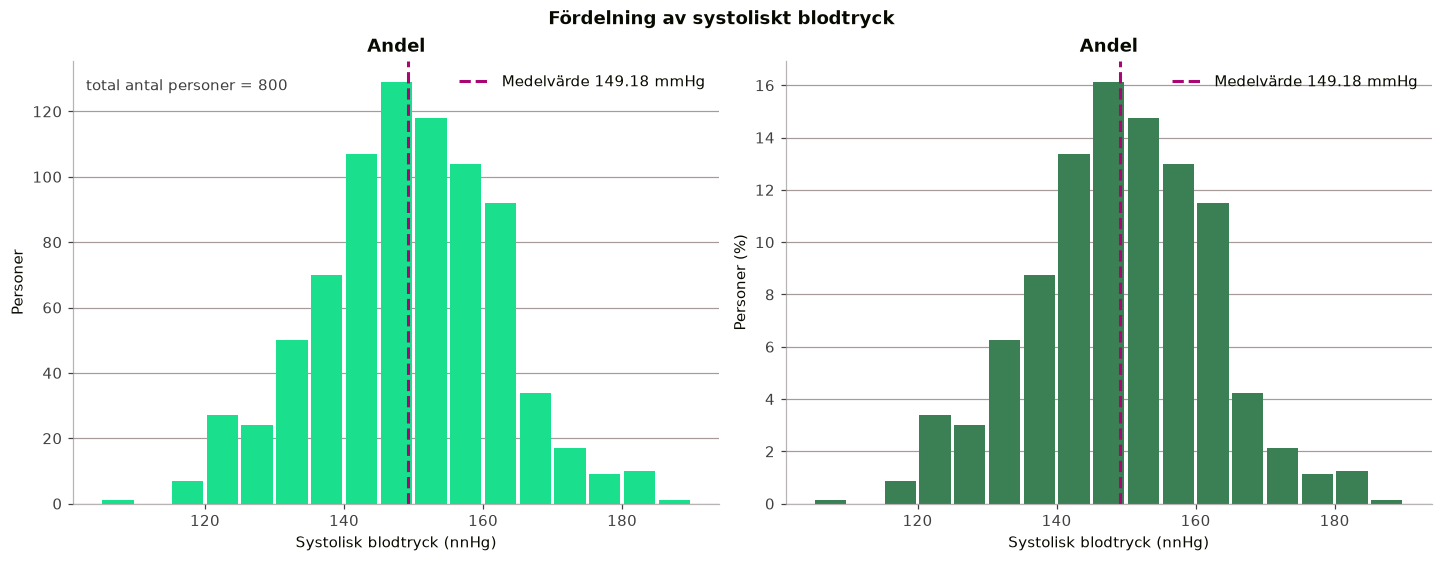

In [12]:

bp_bin_width = 5
bp_bins = np.arange(
    np.floor(bp_values.min() / bp_bin_width) * bp_bin_width,
    np.ceil(bp_values.max() / bp_bin_width) * bp_bin_width + bp_bin_width,
    bp_bin_width,
)

bp_hist_counts, _ = np.histogram(bp_values, bins=bp_bins)
bp_hist_percent = bp_hist_counts / bp_count * 100
bp_bin_centers = (bp_bins[:-1] + bp_bins[1:]) / 2

fig_bp, axes_bp = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for axis, values, color, subtitle, ylabel in [
    (axes_bp[0], bp_hist_counts, COLORS["blood_pressure"], "Andel", "Personer"),
    (axes_bp[1], bp_hist_percent, COLORS["blood_pressure_light"], "Andel", "Personer (%)"),
]:
    axis.bar(bp_bin_centers, values, width=bp_bin_width * 0.90, color=color)
    axis.axvline(bp_mean, color=COLORS["reference"], linestyle="--", linewidth=2, label=f"Medelvärde {bp_mean:.2f} mmHg")
    axis.set(title=subtitle, xlabel="Systolisk blodtryck (nnHg)", ylabel=ylabel)
    axis.legend(loc="upper right")
    style_axis(axis)
axes_bp[0].text(0.02, 0.96, f"total antal personer = {bp_count}", transform=axes_bp[0].transAxes, va="top", color=COLORS["muted"])
fig_bp.suptitle("Fördelning av systoliskt blodtryck", fontweight="bold")
plt.show()


#### 3.2.2 viktfördelning efter kön

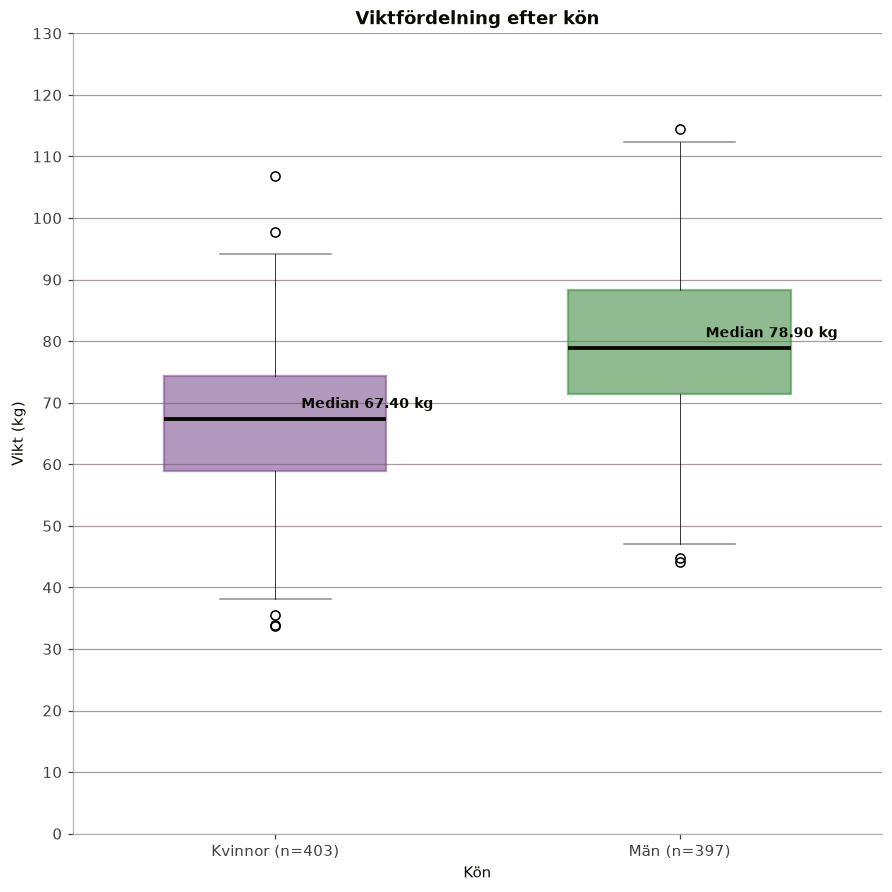

In [13]:
median_weight_by_sex = df.groupby("sex")["weight"].median()
weight_groups = [df.loc[df["sex"] == sex, "weight"].dropna() for sex in SEX_COLUMN]
weight_labels = [f"{label} (n={len(values)})" for label, values in zip(["Kvinnor", "Män"], weight_groups)]



fig_weight, ax_weight = plt.subplots(figsize=(8, 8), layout="constrained")
weight_box = ax_weight.boxplot(
    weight_groups, patch_artist=True, tick_labels=weight_labels, widths=0.55,
    medianprops={"color": COLORS["ink"], "linewidth":2.5},
    whiskerprops={"linewidth":0.5},
    capprops={"marker": None, "markersize":7, "alpha":0.45, "markeredgecolor": COLORS["muted"]},
)
for patch, sex in zip(weight_box["boxes"], SEX_COLUMN):
    patch.set(facecolor=SEX_colors[sex], alpha=0.6, edgecolor=SEX_colors[sex], linewidth=1.5)
for pos, sex in enumerate(SEX_COLUMN, start=1):
    median = median_weight_by_sex.loc[sex]
    ax_weight.annotate(f"Median {median:.2f} kg", (pos, median),
                       xytext=(17, 7), textcoords="offset points", fontsize=9,
                       color=COLORS["ink"], fontweight="bold")
ax_weight.set(title="Viktfördelning efter kön", xlabel="Kön", ylabel="Vikt (kg)")
style_axis(ax_weight)

ax_weight.set_yticks(range(0, 131, 10))
plt.show()

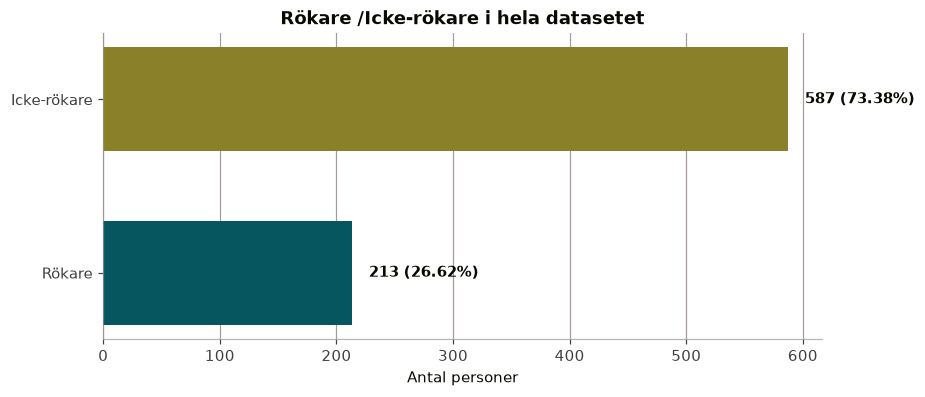

In [14]:
smoking_counts = pd.crosstab(df["sex"], df["smoker"]).reindex(
    index=SEX_COLUMN, columns=SMOKER_COLUMN, fill_value=0
)
smoking_perc = smoking_counts.div(smoking_counts.sum(axis=1), axis=0) * 100
smoking_all_counts = smoking_counts.sum(axis=0)

fig_smoking, ax_smoking = plt.subplots(figsize=(8.3, 3.5), layout="constrained")
smoking_labels = {"No": "Icke-rökare", "Yes": "Rökare"}

for idx, status in enumerate(SMOKER_COLUMN):
    count = int(smoking_all_counts.loc[status])
    ax_smoking.barh(idx, count, color=SMOKING_COLORS[status], height=0.6)
    ax_smoking.text(count + max(smoking_all_counts) * 0.025, idx,
                    f"{count} ({count / smoking_all_counts.sum():.2%})",
                    va="center", fontweight="bold")
ax_smoking.set_yticks(range(len(SMOKER_COLUMN)),[smoking_labels[status] for status in SMOKER_COLUMN])
ax_smoking.invert_yaxis()
ax_smoking.set(title="Rökare /Icke-rökare i hela datasetet", xlabel="Antal personer")
style_axis(ax_smoking, grid_axis="x")
plt.show()

In [15]:
display(smoking_counts.rename(
    index={"F": "Kvinnor", "M": "Män"},
    columns={"No": "Icke-rökare", "Yes":"Rökare"}))

smoker,Icke-rökare,Rökare
sex,,
Kvinnor,287,116
Män,300,97


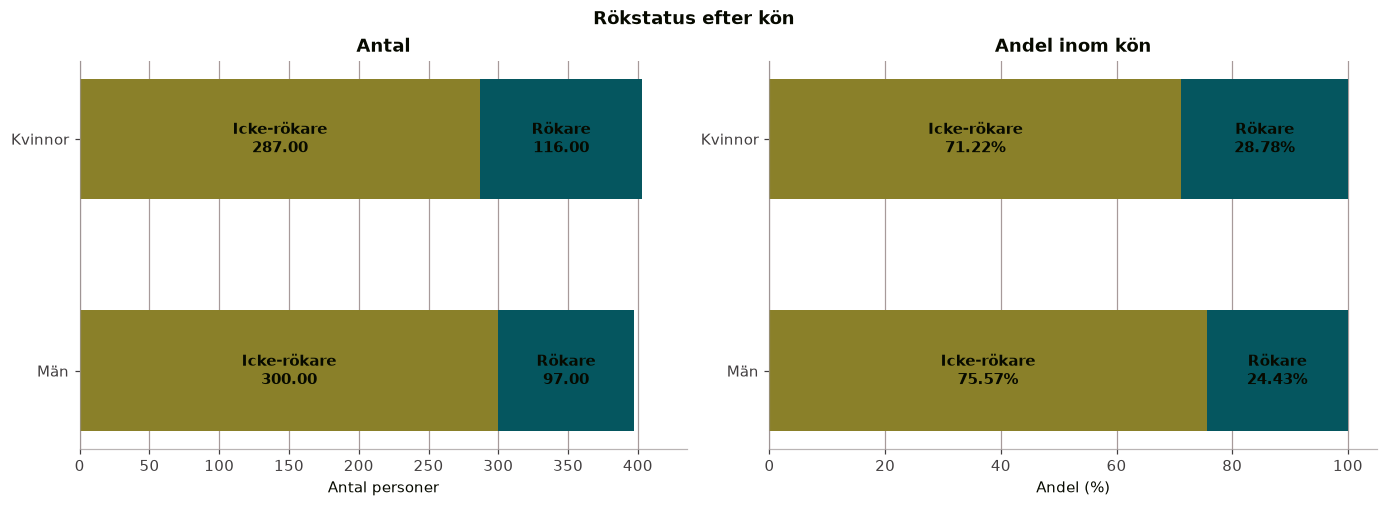

In [16]:
fig_smoking_sex, axes_smoking_sex = plt.subplots(
    1, 2, figsize=(12.5, 4.5), layout="constrained"
)
sex_names = ["Kvinnor", "Män"]
sex_positions = np.arange(len(SEX_COLUMN))
for axis, table, subtitle, xlabel, is_percent in [
    (axes_smoking_sex[0], smoking_counts, "Antal", "Antal personer", False),
    (axes_smoking_sex[1], smoking_perc, "Andel inom kön", "Andel (%)", True),
]:
    left = np.zeros(len(SEX_COLUMN))
    for status in SMOKER_COLUMN:
        widths = table[status].to_numpy()
        bars = axis.barh(sex_positions, widths, left=left, height=0.52,
                         label=smoking_labels[status], color=SMOKING_COLORS[status])
        for bar, value in zip(bars, widths):
            axis.text(bar.get_x() + bar.get_width() / 2,
                          bar.get_y() + bar.get_height() / 2,
                          (f"{smoking_labels[status]}\n{value:.2f}%" if is_percent
                           else f"{smoking_labels[status]}\n{value:.2f}"),
                          ha="center", va="center", color=COLORS["ink"], fontweight="bold", fontsize=10)
        left += widths
    axis.set_yticks(sex_positions, sex_names)
    axis.invert_yaxis()
    axis.set(title=subtitle, xlabel=xlabel)
    axis.set_xlim(0, 105 if is_percent else float(table.sum(axis=1).max()) * 1.08)
    style_axis(axis, grid_axis="x")
# Gruppnamnen är utskrivna i procentstaplarna, så ingen legend täcker figuren.
fig_smoking_sex.suptitle("Rökstatus efter kön", fontweight="bold")
plt.show()

## 4. Simulering kopplad till caset

### 4.1 Andelen personer i datasetet som har sjukdom

 I analysen antar vi att:
 disease = 0 betyder att personen har inte sjukdom och disease = 1 betyder att personen har sjukdomen.

In [17]:
disease_rate = df["disease"].mean()

print(f"Andel personer med sjukdom:  {disease_rate:.4%}")

Andel personer med sjukdom:  5.8750%


Andel personer med sjukdom 5,875%.

### 4.2 Ny grupp med 1 000 slumpade personer

In [18]:
rng_disease = np.random.default_rng(RANDOM_SEED)
simulated_objects = rng_disease.binomial(1, disease_rate, size=SIM_GROUP_SIZE)
simulated_yes_group = simulated_objects.mean()

print(f"Simulerad andel med sjuktom: {simulated_yes_group:.2%}")

Simulerad andel med sjuktom: 5.40%


### 4.3 Jämförelse

In [19]:
print(f" Andel personer med sjukdom i databaset:  {disease_rate:.4%}")
print(f" Simulerad andel med sjuktom:             {simulated_yes_group:.4%}")
print(f" Skillnad:                               {simulated_yes_group - disease_rate:.4%}")

 Andel personer med sjukdom i databaset:  5.8750%
 Simulerad andel med sjuktom:             5.4000%
 Skillnad:                               -0.4750%


## 5. Konfidensintervall - normalapproximation

Värdena beräknades i avsnitt 1.

In [20]:
results = pd.DataFrame({
    "Statistika": ["Medelvärde:",
                   "Standartavvikelse:",
                   "Antal observationer:",
                   "Standardfel:"
                       ],
    "Värde": [
        f"{bp_mean:.4f} mmHg",
        f"{bp_std:.4f} mmHg",
        str(bp_count),
        f"{bp_se:.4f} mmHg"
                       ]
})

display(results.style.hide(axis="index"))

Statistika,Värde
Medelvärde:,149.1786 mmHg
Standartavvikelse:,12.7934 mmHg
Antal observationer:,800
Standardfel:,0.4523 mmHg


### 5.2 Konfidensintervall - felmarginal, gränser

In [24]:
normal_margin = stats.norm.ppf(1 - ALPHA / 2) * bp_se
normal_ci = (bp_mean -normal_margin, bp_mean + normal_margin) 
print(f"Felmarginal: {normal_margin:.4f} mmHg")
print(f"95% konfidensintervall, normalapproximation: [{normal_ci[0]:.4f}, {normal_ci[1]:.4f}] mmHg")

Felmarginal: 0.8865 mmHg
95% konfidensintervall, normalapproximation: [148.2921, 150.0651] mmHg


## 5. Konfidensintervall boostrap

In [ ]:
nn = df["systolic_bp"]
np.random.seed(42)
a = 50000

bootstrap_means = []

for i in range (a):
    sample = np.random.choice(nn, count_p, replace = True)
    sample_mean = sample.mean()
    bootstrap_means.append(sample_mean)

print(len(bootstrap_means))
display(bootstrap_means[:5])


50000


[np.float64(148.545625),
 np.float64(147.935125),
 np.float64(148.327),
 np.float64(148.92762499999998),
 np.float64(149.148)]

### 5.2 stability i bootstrapresultatet

In [ ]:

start = None
lower_bounds = []
upper_bounds = []
count_bootstrap = []
n = 500
max_interations = len(bootstrap_means)
while n < max_interations :
    count_bootstrap.append(n)
    n = n+1000

count_bootstrap.append(max_interations)

changes = []

for n in count_bootstrap:
    lower = np.percentile(bootstrap_means[:n], 2.5)
    upper = np.percentile(bootstrap_means[:n], 97.5)

    lower_bounds.append(lower)
    upper_bounds.append(upper)
    if start is not None:
        change = max(abs(lower - start[0]),
                     abs(upper - start[1]))
        changes.append(change)
        
        
        if 0.005<change<0.15:
            print(f"{n}: {change:.2f}")
        

    start =(lower, upper)
   

1500: 0.05
2500: 0.02
3500: 0.02
4500: 0.02
6500: 0.01
8500: 0.01
10500: 0.01
11500: 0.01
18500: 0.01


### 5.1 boostrap - gränser

In [ ]:
bootstrap_lower_bound = np.percentile(bootstrap_means, 2.5)
bootstrap_upper_bound = np.percentile(bootstrap_means, 97.5)
print(f"95% konfidensintervall ligger lellan {bootstrap_lower_bound:.4f} mmHg och {bootstrap_upper_bound:.4f} mmHg")

95% konfidensintervall ligger lellan 148.2982 mmHg och 150.0629 mmHg


### 5.3 slutsats

In [ ]:

print(f"Konfidensinterval:  95% konfidensintervall ligger mellan {lower_bound:.4f} mmHg och {upper_bound:.4f} mmHg")
print(f"Bootstrap:          95% konfidensintervall ligger lellan {bootstrap_lower_bound:.4f} mmHg och {bootstrap_upper_bound:.4f} mmHg")


Konfidensinterval:  95% konfidensintervall ligger mellan 148.2921 mmHg och 150.0652 mmHg
Bootstrap:          95% konfidensintervall ligger lellan 148.2982 mmHg och 150.0629 mmHg


### förklarning

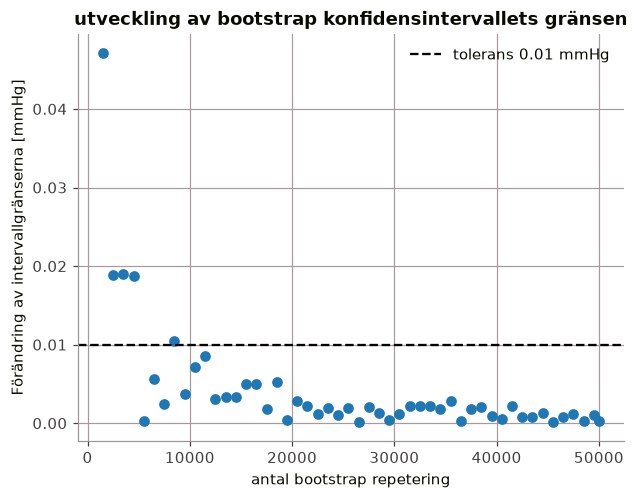

In [ ]:
plt.scatter(count_bootstrap[1:], changes)

plt.axhline(0.01, color="black", linestyle="--", label="tolerans 0.01 mmHg")

plt.xlabel("antal bootstrap repetering")
plt.ylabel("Förändring av intervallgränserna [mmHg]")
plt.title("utveckling av bootstrap konfidensintervallets gränsen")

plt.legend()
plt.grid(True)

plt.show()

## 6. Hypotesprövning

### Påstående :" Rökare har högre medelblodtryck än icke-rökare."

### 6.1 formulera hypoteser

H0: Rökare har inte högre medelblodtryck än icke-rökare. 
H1: Rökare har högre medelblodtryck än icke-rökare.

### 6.2 signifikansnivå

In [ ]:
alpha = 0.05

### 6.3 Data

In [ ]:
smoker = df[df["smoker"] == "Yes"]["systolic_bp"].dropna()
no_smoker = df[df["smoker"] == "No"]["systolic_bp"].dropna()

print("Rökare:" ,  smoker.mean())
print("Icke_rökare:" ,  no_smoker.mean())

Rökare: 149.524882629108
Icke_rökare: 149.05298126064736


### 6.4 T-test p-värde

Welch

In [ ]:
from scipy.stats import ttest_ind

t_stat_w, p_value_w = ttest_ind(
    smoker, no_smoker, equal_var=False, alternative="greater"
)

print("T-statistik:", t_stat_w)
print("P-värde:", p_value_w)

if p_value_w < alpha:
    print("bb")
else:
    print("ss")

T-statistik: 0.4503433193393224
P-värde: 0.32636693716994986
ss


Student

In [ ]:
from scipy.stats import ttest_ind

t_stat_s, p_value_s = ttest_ind(
    smoker, no_smoker, equal_var=True, alternative="greater"
)

print("T-statistik:", t_stat_s)
print("P-värde:", p_value_s)

if p_value_s < alpha:
    print("bb")
else:
    print("ss")

T-statistik: 0.4609102005307389
P-värde: 0.32249430954835984
ss


power

In [ ]:
n_smoker =len(smoker)
n_no_smoker = len(no_smoker)
mean_smoker = smoker.mean()
mean_no_smoker = no_smoker.mean()

std_smoker =smoker.std()
std_no_smoker = no_smoker.std()

In [ ]:
sample_sizes =[100, 300, 700, 1500, 2500]
power_results_w = []
power_results_s = []

rng = np.random.default_rng(42)


print("n=", n)
print("mean smoker" , mean_smoker)
print("mean no smoker", mean_no_smoker)

print("n smoker", n_smoker)
print("n no smoker", n_no_smoker)

for n in sample_sizes:
    significant_w = 0
    significant_s = 0
    n_smoker= int(n*213/800)
    n_no_smoker =n-n_smoker

    print("n", n)
    print("n_smoker", n_smoker)
    print("n_no_smoker", n_no_smoker)

    for i in range(10000):
        sim_smoker = rng.normal(mean_smoker, std_smoker, n_smoker)
        sim_no_smoker = rng.normal(mean_no_smoker, std_no_smoker, n_no_smoker)
        
        t_stat_pw, p_value_pw = stats.ttest_ind(
            sim_smoker,
            sim_no_smoker,
            equal_var=False,
            alternative="greater"
            )
        if i == 0:
            print("welch:", p_value_pw)
        if p_value_pw < 0.05:
            significant_w += 1

        t_stat_ps, p_value_ps = stats.ttest_ind(
            sim_smoker,
            sim_no_smoker,
            equal_var=True,
            alternative="greater"
                    )
        if i == 0:
             print("stu:", p_value_ps)
        if p_value_ps < 0.05:
                    significant_s += 1
        
    
        
    power_w = significant_w /10000
    power_s = significant_s /10000
    power_results_w.append(power_w)
    power_results_s.append(power_s)

    

for i in range(len(sample_sizes)):
    print(sample_sizes[i],
          power_results_w[i],
          power_results_s[i])

n= 50000
mean smoker 149.524882629108
mean no smoker 149.05298126064736
n smoker 213
n no smoker 587
n 100
n_smoker 26
n_no_smoker 74
welch: 0.42022828626792474
stu: 0.4155675854790321
n 300
n_smoker 79
n_no_smoker 221
welch: 0.25854220074367235
stu: 0.24753456366561297
n 700
n_smoker 186
n_no_smoker 514
welch: 0.15628483928040995
stu: 0.1551455843910204
n 1500
n_smoker 399
n_no_smoker 1101
welch: 0.41089672903854335
stu: 0.4114473567058953
n 2500
n_smoker 665
n_no_smoker 1835
welch: 0.24884129831752813
stu: 0.24005879526520768
100 0.0645 0.0689
300 0.0885 0.0939
700 0.1137 0.121
1500 0.1526 0.163
2500 0.1998 0.2115


In [ ]:
print("mean smoker:" , mean_smoker)
print("mean no smoker:", mean_no_smoker)

print("difference:", mean_smoker - mean_no_smoker)

print("std smoker, no_smoker:" , std_smoker , std_no_smoker)

mean smoker: 149.524882629108
mean no smoker: 149.05298126064736
difference: 0.47190136846063524
std smoker, no_smoker: 13.26780009812125 12.626037772560291
